# Taller F03 — Suavizamiento exponencial y ETS

## Contexto

Retomamos las 120 semanas sintéticas de demanda industrial de F02, con persistencia y tendencia suave, sin estacionalidad impuesta. Conservamos las últimas 12 semanas como test.

## Objetivo

Ajustar e interpretar SES, Holt y AutoETS, evaluar frente a naive y diagnosticar residuos. Todas las herramientas se trabajaron en F02_03; decida cómo combinarlas con mayor autonomía.

> **Nota sobre el benchmark:** en este taller se utiliza naive como benchmark común para facilitar la comparación entre todos los estudiantes. En el proyecto integrador deben utilizar el benchmark principal que seleccionaron y justificaron en el Hito 2.

**Total: 10 puntos.** SES 2; alpha 1; Holt 2; forecast y métricas 2; AutoETS 1; residuos 1; interpretación final 1.

> No modifique las celdas bloqueadas. Ajuste exclusivamente con train.

In [15]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

rng = np.random.default_rng(2026)

n = 120
semana = np.arange(1, n + 1)

eps = rng.normal(0, 4, n)
demanda = np.zeros(n)
demanda[0] = 100

for t in range(1, n):
    demanda[t] = 100 + 0.55 * (demanda[t-1] - 100) + 0.10 * t + eps[t]

df = pd.DataFrame({"semana": semana, "demanda": demanda})
df.head()

import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, Holt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.tsa.stattools import acf
from statsforecast.models import AutoETS

h = 12
train = df.iloc[:-h].copy()
test = df.iloc[-h:].copy()
y_train = train["demanda"].to_numpy(dtype=float)
y_test = test["demanda"].to_numpy(dtype=float)
forecast_naive = np.repeat(y_train[-1], h)
assert train["semana"].max() < test["semana"].min()

## 1. Ajuste SES — 2 puntos

Ajuste `ses` sobre `y_train`, con inicialización estimada y optimización automática. Guarde `alpha_ses` y `nivel_final` desde el resultado. No proporcione alpha fijo.

In [16]:
ses = SimpleExpSmoothing(y_train, initialization_method="estimated").fit(optimized=True)
alpha_ses = ses.params["smoothing_level"]
nivel_final = ses.forecast(h)

print(f'Alpha: {alpha_ses}')
print(f'Nivel final: {nivel_final[0]}')

Alpha: 0.7210590215867898
Nivel final: 126.23723793546033


## 2. Interpretación de alpha — 1 punto

En máximo 100 palabras interprete `alpha_ses`. Compare valores próximos a 0 y a 1 y explique por qué alpha alto no garantiza menor error en test. Evaluación manual: 0.4 por memoria/reacción, 0.3 por conectar con el valor estimado y 0.3 por distinguir ajuste de evaluación.

El valor de 0.7210590215867898 para el alpha le da mayor peso a la última observación que a la historia que tiene en los anteriores pasos, reaccionando a cambios rápidamente. Pero esto no garantiza  menor error en test a largo plazo, debido a que un alpha alto solo minimiza el error a un horizonte cercano (por ejemplo, $h=1$)

## 3. Holt — 2 puntos

Ajuste `holt` con inicialización estimada y optimización automática. Extraiga `nivel_holt` y `tendencia_holt` finales. Ajuste además `amortiguado` con tendencia amortiguada e idéntico criterio de inicialización. Guarde su `phi`. La tendencia se expresa en unidades de demanda por semana.

In [17]:
# Holt Lineal
holt_lin = Holt(y_train, initialization_method="estimated").fit(optimized=True)

alpha_holt = holt_lin.params["smoothing_level"]
beta_holt = holt_lin.params["smoothing_trend"]

nivel_holt = holt_lin.level[-1]
tendencia_holt = holt_lin.trend[-1]

# Holt Amortiguado
holt_damped = Holt(
    y_train, damped_trend=True, initialization_method="estimated"
).fit(optimized=True)

alpha_damped = holt_damped.params["smoothing_level"]
beta_damped = holt_damped.params["smoothing_trend"]
phi = holt_damped.params["damping_trend"]

nivel_damped = holt_damped.level[-1]
tendencia_damped = holt_damped.trend[-1]

print(f'-----Holt Lineal-----')
print(f'Alpha: {alpha_holt}')
print(f'Beta: {beta_holt}')
print(f'Nivel: {nivel_holt}')
print(f'Tendencia: {tendencia_holt}')
print(f'-----Holt Amortiguado-----')
print(f'Alpha: {alpha_damped}')
print(f'Beta: {beta_damped}')
print(f'Phi: {phi}')
print(f'Nivel: {nivel_damped}')
print(f'Tendencia: {tendencia_damped}')


-----Holt Lineal-----
Alpha: 0.7052662367483423
Beta: 0.0
Nivel: 126.32539685414258
Tendencia: 0.24823782921149623
-----Holt Amortiguado-----
Alpha: 0.7058683573918685
Beta: 0.0
Phi: 0.995
Nivel: 126.29786305419832
Tendencia: 0.1810507170339038


## 4. Forecast y métricas — 2 puntos

Implemente `mae`, `rmse` y `mase` como en Semana 2. MASE debe devolver `np.nan` si la escala naive de un paso de train es prácticamente cero.

Construya `pronosticos` con claves `naive`, `SES`, `Holt` y `Holt amortiguado`, cada una con un arreglo de longitud `h`. Cree `metricas`, DataFrame indexado por esos nombres, con columnas `MAE`, `RMSE`, `MASE`, usando el mismo test. No reentrene dentro de test.

In [22]:
def mae(y_true, y_pred):
  return mean_absolute_error(y_true, y_pred)


def rmse(y_true, y_pred):
  return np.sqrt(mean_squared_error(y_true, y_pred))


def mase(y_train, y_true, y_pred):
  scale = np.mean(np.abs(np.diff(y_train)))
  if scale < np.finfo(float).eps or np.isnan(scale):
    return np.nan
  return np.mean(np.abs(y_true - y_pred)) / scale

h = len(y_test)

forecasts = {
    "naive": np.repeat(y_train[-1], h),
    "SES": np.asarray(ses.forecast(h)).ravel(),
    "Holt": np.asarray(holt_lin.forecast(h)).ravel(),
    "Holt amortiguado": np.asarray(holt_damped.forecast(h)).ravel(),
}

keys = ["naive", "SES", "Holt", "Holt amortiguado"]
metricas_lista = []

for k in keys:
  pred = forecasts[k]
  metricas_lista.append({
      "MAE": mae(y_test, pred),
      "RMSE": rmse(y_test, pred),
      "MASE": mase(y_train, y_test, pred),
  })

df_metricas = pd.DataFrame(metricas_lista, index=keys)
print("\n--- TABLA DE MÉTRICAS ---")
print(df_metricas)


--- TABLA DE MÉTRICAS ---
                       MAE      RMSE      MASE
naive             4.295609  5.053712  1.208805
SES               4.295609  4.988559  1.208805
Holt              4.238503  5.351796  1.192735
Holt amortiguado  4.178159  5.182017  1.175754


## 5. AutoETS — 1 punto

Ajuste `auto` solo con train usando `season_length=1` y `model="ZZN"`. Guarde `modelo_ets` (nombre legible del modelo) y `forecast_auto`; incorpore `AutoETS` a `pronosticos` y su fila a `metricas`. Interprete el nombre en la conclusión final.

In [33]:
# 1. Ajuste y pronóstico de AutoETS
auto_ets = AutoETS(season_length=1, model="ZZN").fit(np.asarray(y_train, dtype=float))
print(f"Modelo AutoETS seleccionado: {auto_ets.model_['method']}")

forecast_auto = auto_ets.predict(h=h)["mean"]
assert len(forecast_auto) == h, f"Se esperaban {h} pasos, se obtuvieron {len(forecast_auto)}"

forecasts["AutoETS"] = forecast_auto

df_metricas = pd.DataFrame(
    {
        k: {
            "MAE": mae(y_test, pred),
            "RMSE": rmse(y_test, pred),
            "MASE": mase(y_train, y_test, pred),
        }
        for k, pred in forecasts.items()
    }
).T

print("\n--- TABLA DE MÉTRICAS ACTUALIZADA ---")
print(df_metricas)

Modelo AutoETS seleccionado: ETS(M,N,N)

--- TABLA DE MÉTRICAS ACTUALIZADA ---
                       MAE      RMSE      MASE
naive             4.295609  5.053712  1.208805
SES               4.295609  4.988559  1.208805
Holt              4.238503  5.351796  1.192735
Holt amortiguado  4.178159  5.182017  1.175754
AutoETS           4.295609  4.983204  1.208805


## 6. Diagnóstico de residuos — 1 punto

Calcule `residuos` de AutoETS en unidades originales usando ajustes de un paso en train y `media_residuos`. Construya gráfico temporal y ACF hasta rezago 20, omitiendo cero. Guarde también `acf_residuos = acf(residuos, nlags=20)` (incluye lag 0). Los cálculos se verifican automáticamente; use los gráficos para sustentar la interpretación final.

Media de residuos: 0.3550
Desv. estándar de residuos: 4.3263
Longitud acf_residuos: 21


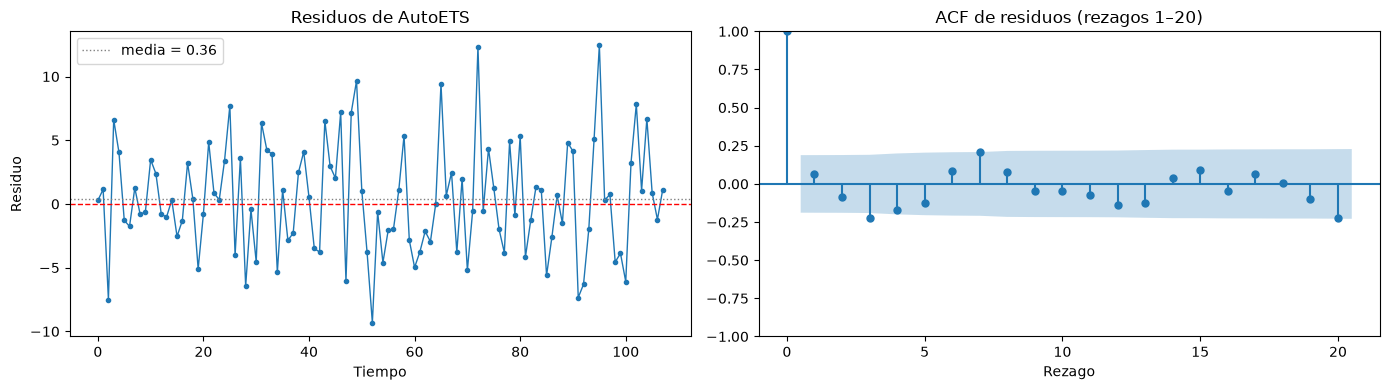

In [36]:
y_arr = np.asarray(y_train, dtype=float)
fitted = np.asarray(auto_ets.predict_in_sample()["fitted"], dtype=float)

residuos = y_arr - fitted
media_residuos = residuos.mean()

acf_residuos = acf(residuos, nlags=20)

print(f"Media de residuos: {media_residuos:.4f}")
print(f"Desv. estándar de residuos: {residuos.std(ddof=1):.4f}")
print(f"Longitud acf_residuos: {len(acf_residuos)}")  # 21

idx = y_train.index if hasattr(y_train, "index") else np.arange(len(residuos))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].plot(idx, residuos, marker="o", ms=3, lw=1)
axes[0].axhline(0, color="red", ls="--", lw=1)
axes[0].axhline(media_residuos, color="gray", ls=":", lw=1, label=f"media = {media_residuos:.2f}")
axes[0].set_title("Residuos de AutoETS")
axes[0].set_xlabel("Tiempo")
axes[0].set_ylabel("Residuo")
axes[0].legend()

plot_acf(residuos, lags=20, ax=axes[1])
axes[1].set_title("ACF de residuos (rezagos 1–20)")
axes[1].set_xlabel("Rezago")

plt.tight_layout()
plt.show()

## 7. Interpretación comparativa — 1 punto

En máximo **180 palabras**, responda:

> ¿El modelo de suavizamiento exponencial mejora realmente al benchmark? Justifique usando desempeño fuera de muestra, estructura de la serie y diagnóstico de residuos.

Identifique el mejor suavizamiento, cite MAE, RMSE y MASE frente a naive, decodifique `modelo_ets`, interprete media y ACF de residuos y explique qué estructura queda sin representar. Distinga MASE menor que 1 de superar naive en test. No declare un ganador universal ni seleccione el modelo final del proyecto.

Evaluación manual: 0.4 por comparación numérica y temporal; 0.2 por interpretar ETS; 0.3 por conectar estructura y residuos; 0.1 por reconocer límites.

Fuera de los datos que se usaron para el entrenamiento se ven mejoras mixtas frente al *Naive*, el *Holt Amortiguado* mostrando mejoras en el MAE ($4.178$) y MASE ($1.175$), mientras que el *AutoETS* mejora el RMSE ($4.983$ vs $5.053$).

El *AutoETS* se interpreta como un ETS(M,N,N), donde se tiene error multiplicativo sin tendencia ni estacionalidad, lo que refleja un ajuste plano. Los residuos muestran una media de $0.355$ y un ACF con rezagos dentro de las bandas de confianza (confirmando ruido blanco), esto muestra una correcta elección de la estructura sistemática de la serie. Aunque, los problemas de los choques dentro de la serie siguen sin ser representados por el modelo. Por esto, y teniendo en cuenta que el MASE de todos es mayor a 1, no se puede decidir un modelo definitivo, siempre se debe seleccionar de acuerdo a la métrica que se quiera minimizar